# Automating Protege Example

This notebook is an example of how to run Protege automatically, instead of interactively. This is useful when you already have catalogued anomalies and you want to check the performance. It uses the MGCLS example from https://arxiv.org/abs/2411.04188. Check the paper for links to the catalogue and data used here. Note that the original MGCLS fits files need to have their dimensionality collapsed before loading. I recommend doing this once and saving to disk.

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

from astronomaly.preprocessing import image_preprocessing
from astronomaly.data_management import image_reader
from astronomaly.feature_extraction import byol_features
from astronomaly.dimensionality_reduction import pca
from astronomaly.anomaly_detection import protege, human_loop_learning
 
 # Nice interactive package can be installed with pip install ipympl
%matplotlib widget

## Setup

In [2]:
# ── Paths ──────────────────────────────────────────────────────────────────
root_dir = "/Users/kamoheloleriba/Downloads/"
image_dir = root_dir + 'Farcsec_collapsed'
catalogue_file = root_dir + 'mgcls.protege-main/catalogue/protege_catalogue.csv'
output_dir = root_dir + 'MGCLS_enhanced/astronomaly_output/'
force_rerun = False

# ── Transform switch ────────────────────────────────────────────────────────
# Options: 'sigma_clipped' | 'inverse_sinh'
transform_type = 'sigma_clipped'

if transform_type == 'sigma_clipped':
    image_transform_function = [
        image_preprocessing.image_transform_sigma_clipping,
        image_preprocessing.image_transform_remove_negatives,
        image_preprocessing.image_transform_scale,
    ]
elif transform_type == 'inverse_sinh':
    image_transform_function = [
        image_preprocessing.image_transform_inverse_sinh,
        image_preprocessing.image_transform_scale,
    ]

display_transform_function = image_transform_function


## Read the data

In [3]:
os.makedirs(output_dir, exist_ok=True)
catalogue = pd.read_csv(catalogue_file)
catalogue = catalogue.rename(columns={'obj_size_pixels': 'obj_size'})

image_dataset_full = image_reader.ImageDataset(
    directory=image_dir,
    window_size=128,
    output_dir=output_dir,
    plot_square=False,
    transform_function=image_transform_function,
    display_transform_function=display_transform_function,
    display_interpolation=None,
    adaptive_sizing=True,
    min_window_size=0,
    suppress_printing=True,
    catalogue=catalogue,
)

A catalogue of  6161 sources has been provided.


## Extract BYOL features

In [4]:
features_file = output_dir + 'BYOL_Features.parquet'

if force_rerun or not os.path.exists(features_file):
    byol_pipeline = byol_features.BYOL_Features(
        output_dir=output_dir,
        n_epochs=100,
        batch_size=32,
        num_workers=16,
        force_rerun=force_rerun,
    )
    byol_pipeline.train_byol(image_dataset_full)
    features = byol_pipeline.run_on_dataset(image_dataset_full)
    features.to_parquet(features_file)
else:
    features = pd.read_parquet(features_file)
    print('Loaded features from', features_file)

print('Features shape:', features.shape)



Loaded features from /Users/kamoheloleriba/Downloads/MGCLS_enhanced/astronomaly_output/BYOL_Features.parquet
Features shape: (6161, 1280)


## PCA reduction and evaluation set

In [5]:
pipeline_pca = pca.PCA_Decomposer(
    force_rerun=True,
    output_dir=output_dir,
    threshold=0.95,
)
features_pca = pipeline_pca.run(features)
print('Features shape:', features_pca.shape)

catalogue_evaluation = catalogue[catalogue['evaluation_subset_author_ML_score'] != -1].copy()
catalogue_evaluation.index = catalogue_evaluation['objid']
features_eval = features_pca.loc[features_pca.index.isin(catalogue_evaluation.index)]

labels = catalogue_evaluation[['evaluation_subset_author_ML_score']].rename(
    columns={'evaluation_subset_author_ML_score': 'human_label'})
labels['binary_label'] = ((labels['human_label'] == 4) | (labels['human_label'] == 5)).astype(int)

Running PCA_Decomposer ...
Total explained variance: 0.9500383
Done! Time taken: 0.49053311347961426 s
Features shape: (6161, 45)


## Run Protege

In [6]:
def run_GP_active_learning(features, labels, input_anomaly_scores, output_dir,
                           steps=10, initial_steps=None, N_labels=100, ei_tradeoff=0.5):
    anomaly_scores = input_anomaly_scores.copy()
    anomaly_scores['human_label'] = [-1] * len(anomaly_scores)
    pipeline_active_learning = protege.GaussianProcess(
        features, force_rerun=True, output_dir=output_dir, ei_tradeoff=ei_tradeoff)

    if initial_steps is not None:
        anomaly_scores.sort_values('score', ascending=False, inplace=True)
        inds = anomaly_scores[anomaly_scores.human_label == -1].index[:initial_steps]
        anomaly_scores.loc[inds, 'human_label'] = labels.loc[inds, 'human_label']
        features_with_labels = pipeline_active_learning.combine_data_frames(features, anomaly_scores)
        active_output = pipeline_active_learning.run(features_with_labels)
        anomaly_scores['trained_score'] = active_output['trained_score']
        anomaly_scores['acquisition'] = active_output['acquisition']
    else:
        initial_steps = 0

    for i in range(initial_steps // steps, N_labels // steps):
        anomaly_scores.sort_values('acquisition', ascending=False, inplace=True)
        inds = anomaly_scores[anomaly_scores.human_label == -1].index[:steps]
        anomaly_scores.loc[inds, 'human_label'] = labels.loc[inds, 'human_label']
        features_with_labels = pipeline_active_learning.combine_data_frames(features, anomaly_scores)
        active_output = pipeline_active_learning.run(features_with_labels)
        anomaly_scores['trained_score'] = active_output['trained_score']
        anomaly_scores['acquisition'] = active_output['acquisition']

    return anomaly_scores

In [7]:
initial_steps = 10

sorted_features = features_eval.sort_values(features_eval.columns[0])
selected_inds = np.linspace(0, len(sorted_features) - 1, initial_steps, dtype='int')
selected_inds = sorted_features.index[selected_inds]
anomaly_scores = pd.DataFrame(
    [0] * len(sorted_features),
    index=sorted_features.index,
    columns=['score'])
anomaly_scores.loc[selected_inds] = 1

pipeline_score_converter = human_loop_learning.ScoreConverter(
    force_rerun=True, output_dir=output_dir)
anomaly_scores = pipeline_score_converter.run(anomaly_scores)

active_output = run_GP_active_learning(
    features_eval,
    labels,
    anomaly_scores,
    output_dir,
    steps=10,
    initial_steps=10,
    N_labels=600,
    ei_tradeoff=0,
)

Running ScoreConverter ...
Running anomaly score rescaler...
Done! Time taken: 0.003991603851318359 s
Running GaussianProcess ...
Running GP regression with 10 training points
Done! Time taken: 0.026255130767822266 s
Running GaussianProcess ...
Running GP regression with 20 training points
Done! Time taken: 0.03625202178955078 s
Running GaussianProcess ...
Running GP regression with 30 training points
Done! Time taken: 0.043212175369262695 s


/Users/kamoheloleriba/ml-project/venv/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Running GaussianProcess ...
Running GP regression with 40 training points
Done! Time taken: 0.03788495063781738 s
Running GaussianProcess ...
Running GP regression with 50 training points
Done! Time taken: 0.03160429000854492 s
Running GaussianProcess ...
Running GP regression with 60 training points
Done! Time taken: 0.03220105171203613 s
Running GaussianProcess ...
Running GP regression with 70 training points
Done! Time taken: 0.033666133880615234 s
Running GaussianProcess ...
Running GP regression with 80 training points
Done! Time taken: 0.034903764724731445 s
Running GaussianProcess ...
Running GP regression with 90 training points
Done! Time taken: 0.03099989891052246 s
Running GaussianProcess ...
Running GP regression with 100 training points
Done! Time taken: 0.03016805648803711 s
Running GaussianProcess ...
Running GP regression with 110 training points
Done! Time taken: 0.05978679656982422 s
Running GaussianProcess ...
Running GP regression with 120 training points
Done! Tim

In [8]:
# The final Protege score gives the order in which sources would be inspected.
ranked_ids = active_output.sort_values(
    "trained_score", ascending=False
).index

ranked_labels = labels.loc[ranked_ids, "binary_label"].astype(int)

# Each count is the number of high-interest sources found by that rank.
for rank in (25, 50, 100):
    found = int(ranked_labels.iloc[:rank].sum())
    print(f"First {rank} sources inspected: {found} high-interest sources found")

First 25 sources inspected: 10 high-interest sources found
First 50 sources inspected: 16 high-interest sources found
First 100 sources inspected: 28 high-interest sources found


In [15]:
# These are the source IDs in the first 20 positions of the final ranking.
top_20_ids = active_output.sort_values('trained_score', ascending=False).head(20).index

# The accompanying table keeps the scores and labels for those sources.
top_20_info = (active_output.sort_values("trained_score", ascending=False).head(20))

# Resetting the index keeps each source ID in the saved CSV.
top_20_info = top_20_info.reset_index()

# These columns show the ranking information used in the comparison.
top_20_info[["index", "score", "human_label", "trained_score", "acquisition"]]

top_20_info.to_csv("BYOL_PROTEGE_Top20_info.csv", index=False)

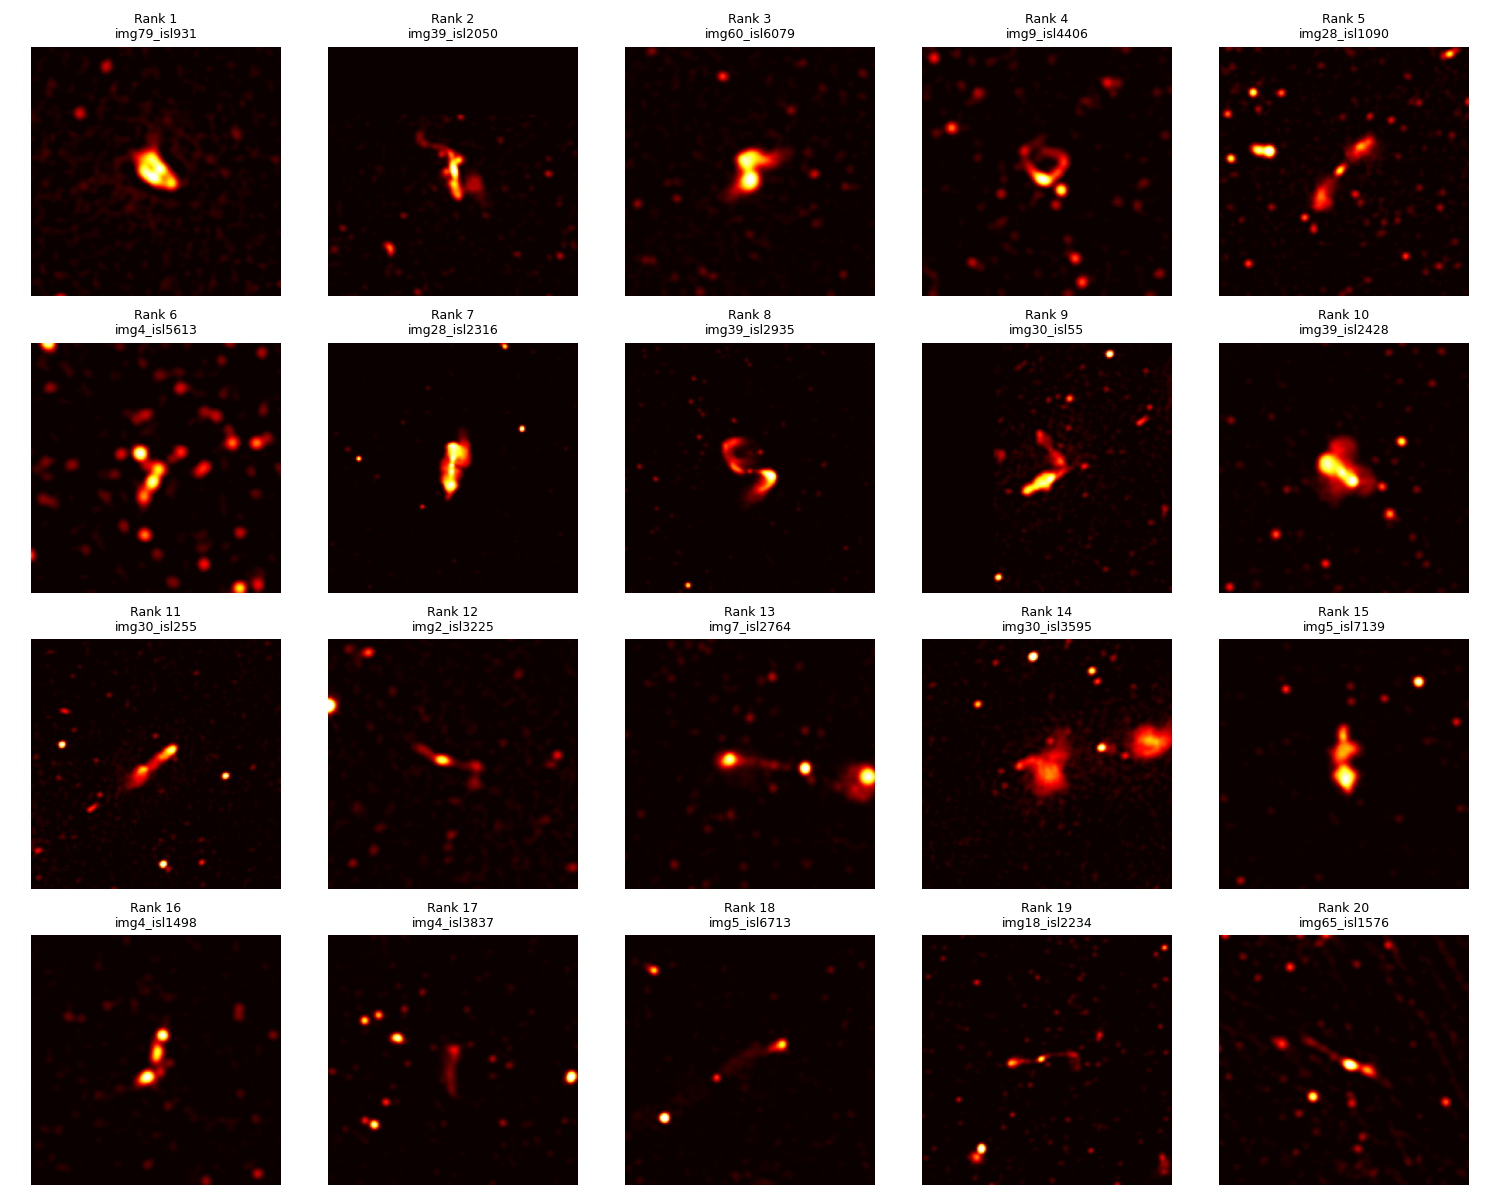

In [14]:
from PIL import Image
import matplotlib.pyplot as plt


fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.flatten()

def asinh_display(img, stretch=5.0):
    # Non-finite FITS values become background pixels in the display.
    image = np.nan_to_num(np.asarray(img, dtype=float),nan=0.0, posinf=0.0, neginf=0.0)
    # Negative values are hidden, while zero-padded edges stay black.
    image = np.clip(image, 0, None)

    positive = image[image > 0]
    # A cutout with no positive pixels has nothing to stretch.
    if positive.size == 0:
        return np.zeros_like(image)

    # The high percentile stops a few bright pixels setting the whole scale.
    upper = np.percentile(positive, 99.9)
    scaled = np.clip(image / upper, 0, 1)
    # Asinh brings out faint emission while compressing the bright end.
    return np.arcsinh(stretch * scaled) / np.arcsinh(stretch)

# This affects displayed cutouts only, the feature input is unchanged.
image_dataset_full.display_transform_function = asinh_display
for i, obj_id in enumerate(top_20_ids):

    image_data = image_dataset_full.get_display_data(obj_id)
    image_data.seek(0)

    # The FITS cutout has already been stretched for display by the dataset.
    with Image.open(image_data) as loaded:
        img = loaded.convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(f"Rank {i+1}\n{obj_id}",fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
fig.savefig(os.path.join(output_dir, "BYOL_Top20_.png"), dpi=300, bbox_inches="tight")
plt.show()


## Plot recall

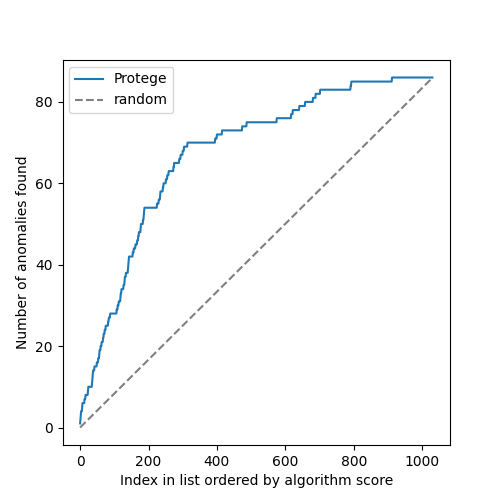

BYOL Discovery AUC = 0.7841731892720998


In [11]:
colours_dict = {'protege': 'C0'}
labels_dict = {'protege': 'Protege'}

sorted_inds = active_output.sort_values('trained_score', ascending=False).index
anom_inds = labels[labels['binary_label'] == 1].index
found_inds = sorted([np.where(sorted_inds == i)[0][0] for i in anom_inds])
recall = np.zeros(len(sorted_inds))
for i in found_inds:
    recall[i:] += 1

x = np.arange(len(recall))
random_recall = x * len(anom_inds) / len(sorted_inds)

plt.figure(figsize=(5, 5))
plt.plot(x, recall, color=colours_dict['protege'], label=labels_dict['protege'])
plt.plot(x, random_recall, color='grey', linestyle='dashed', label='random')
plt.legend()
plt.xlabel('Index in list ordered by algorithm score')
plt.ylabel('Number of anomalies found')
plt.show()

# Fractions put inspected sources and discoveries on the same 0-to-1 scale.
recall_fraction = recall / len(anom_inds)
x_fraction = x / len(sorted_inds)

# A larger area means more high-interest sources appear early in the ranking.
byol_auc = np.trapezoid(recall_fraction, x_fraction)

print("BYOL Discovery AUC =", byol_auc)

# The saved curve can be compared with DINOv3 without rerunning Protege.
np.savez("BYOL_discovery_curve.npz", x=x_fraction, recall=recall_fraction, auc=byol_auc)

# BYOL
byol_x = x_fraction.copy()
byol_recall = recall_fraction.copy()